XOR predictions:
  [0 0] -> 0.000 -> class 0
  [0 1] -> 0.999 -> class 1
  [1 0] -> 0.999 -> class 1
  [1 1] -> 0.002 -> class 0

Moons test accuracy: 96.00%


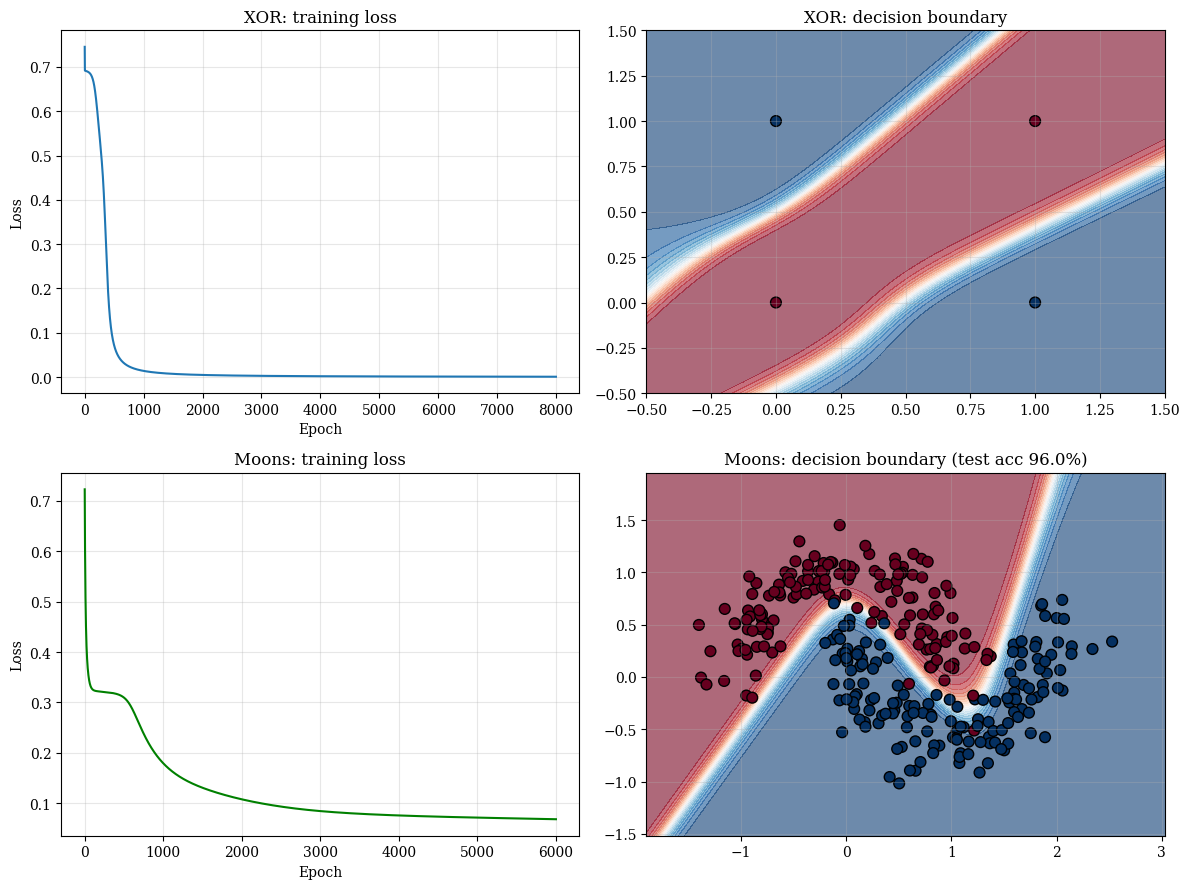

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

plt.rcParams["font.family"] = "serif"

from sklearn.datasets import make_moons

def sigmoid(z): return 1 / (1 + np.exp(-z))

class NeuralNetwork:
    def __init__(self, n_in, n_hidden, lr=0.5, seed=1):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, 1, (n_in, n_hidden)); self.b1 = np.zeros((1, n_hidden))
        self.W2 = rng.normal(0, 1, (n_hidden, 1));    self.b2 = np.zeros((1, 1))
        self.lr = lr

    def forward(self, X):
        self.a1 = sigmoid(X @ self.W1 + self.b1)
        self.a2 = sigmoid(self.a1 @ self.W2 + self.b2)
        return self.a2

    def backward(self, X, y):
        m = len(X)
        d2 = (self.a2 - y)                              # output error (cross-entropy + sigmoid)
        d1 = (d2 @ self.W2.T) * self.a1 * (1 - self.a1) # error propagated back to hidden layer
        self.W2 -= self.lr * self.a1.T @ d2 / m;  self.b2 -= self.lr * d2.mean(0, keepdims=True)
        self.W1 -= self.lr * X.T @ d1 / m;        self.b1 -= self.lr * d1.mean(0, keepdims=True)

    def fit(self, X, y, epochs=5000):
        losses = []
        for _ in range(epochs):
            p = self.forward(X)
            losses.append(-np.mean(y * np.log(p + 1e-9) + (1 - y) * np.log(1 - p + 1e-9)))
            self.backward(X, y)
        return losses

    def predict(self, X): return (self.forward(X) > 0.5).astype(int)

def boundary(ax, model, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:,0].min()-.5, X[:,0].max()+.5, 200),
                         np.linspace(X[:,1].min()-.5, X[:,1].max()+.5, 200))
    z = model.forward(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=20, cmap="RdBu", alpha=.6)
    ax.scatter(X[:,0], X[:,1], c=y.ravel(), cmap="RdBu", edgecolors="k", s=60)
    ax.set_title(title)

# ---------- Data set 1: XOR
Xx = np.array([[0,0],[0,1],[1,0],[1,1]], float)
yx = np.array([[0],[1],[1],[0]], float)
nn1 = NeuralNetwork(2, 4, lr=1.0)
loss1 = nn1.fit(Xx, yx, 8000)
print("XOR predictions:")
for xi, p in zip(Xx, nn1.forward(Xx)):
    print(f"  {xi.astype(int)} -> {p[0]:.3f} -> class {int(p[0] > .5)}")

# ---------- Data set 2: make_moons
Xm, ym = make_moons(300, noise=0.2, random_state=0)
ym = ym.reshape(-1, 1)
idx = np.random.default_rng(0).permutation(300)
tr, te = idx[:225], idx[225:]
nn2 = NeuralNetwork(2, 8, lr=1.0)
loss2 = nn2.fit(Xm[tr], ym[tr], 6000)
acc = (nn2.predict(Xm[te]) == ym[te]).mean()
print(f"\nMoons test accuracy: {acc*100:.2f}%")

fig, ax = plt.subplots(2, 2, figsize=(12, 9))
ax[0,0].plot(loss1); ax[0,0].set_title("XOR: training loss"); ax[0,0].set_xlabel("Epoch"); ax[0,0].set_ylabel("Loss")
boundary(ax[0,1], nn1, Xx, yx, "XOR: decision boundary")
ax[1,0].plot(loss2, color="green"); ax[1,0].set_title("Moons: training loss"); ax[1,0].set_xlabel("Epoch"); ax[1,0].set_ylabel("Loss")
boundary(ax[1,1], nn2, Xm, ym, f"Moons: decision boundary (test acc {acc*100:.1f}%)")
for a in ax.ravel(): a.grid(alpha=.3)
plt.tight_layout(); plt.show()